In [1]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

In [2]:
df = pd.read_excel('Online Retail.xlsx')

display(df.head())
print(f"Shape dataset: {df.shape}")
df.info()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Shape dataset: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [3]:
print(f"Jumlah baris sebelum pembersihan: {df.shape[0]}")
print(f"Jumlah invoice sebelum pembersihan: {df['InvoiceNo'].nunique()}")

df = df.dropna(subset=['Description'])

df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.startswith('C')]

df = df[df['Quantity'] > 0]

print(f"\nJumlah baris sesudah pembersihan: {df.shape[0]}")
print(f"Jumlah invoice sesudah pembersihan: {df['InvoiceNo'].nunique()}")

Jumlah baris sebelum pembersihan: 541909
Jumlah invoice sebelum pembersihan: 25900

Jumlah baris sesudah pembersihan: 530693
Jumlah invoice sesudah pembersihan: 20136


C:\Users\W I N D O W S\AppData\Local\Temp\ipykernel_15800\2471157893.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_products.values, y=top_10_products.index, palette='viridis')


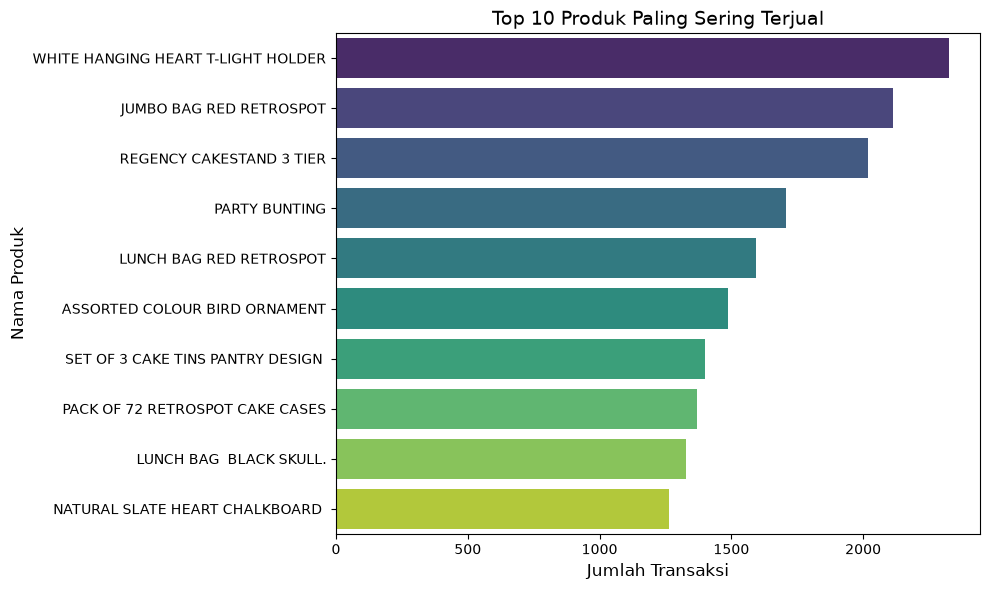

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
top_10_products = df['Description'].value_counts().head(10)

sns.barplot(x=top_10_products.values, y=top_10_products.index, palette='viridis')
plt.title('Top 10 Produk Paling Sering Terjual', fontsize=14)
plt.xlabel('Jumlah Transaksi', fontsize=12)
plt.ylabel('Nama Produk', fontsize=12)
plt.tight_layout()
plt.show()

In [6]:
df['Description'] = df['Description'].str.strip()

basket = (df.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket_sets = (basket > 0).astype(int)

print(f"Dimensi basket_sets: {basket_sets.shape}")
df['Description'] = df['Description'].str.strip()

basket = (df.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket_sets = (basket > 0).astype(int)

print(f"Dimensi basket_sets: {basket_sets.shape}")

Dimensi basket_sets: (20136, 4065)
Dimensi basket_sets: (20136, 4065)


In [7]:
frequent_itemsets = fpgrowth(basket_sets, min_support=0.01, use_colnames=True)

print(f"Jumlah frequent itemsets yang ditemukan: {len(frequent_itemsets)}")
display(frequent_itemsets.head())

C:\Users\W I N D O W S\AppData\Roaming\Python\Python315\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


Jumlah frequent itemsets yang ditemukan: 1853


,support,itemsets
0,0.112237,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
1,0.022795,frozenset({KNITTED UNION FLAG HOT WATER BOTTLE})
2,0.021305,frozenset({RED WOOLLY HOTTIE WHITE HEART.})
3,0.018872,frozenset({SET 7 BABUSHKA NESTING BOXES})
4,0.015246,frozenset({WHITE METAL LANTERN})


In [8]:
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)

display(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head())

top_3_rules = rules.sort_values('lift', ascending=False).head(3)

print("\n=== Tiga Aturan Terbaik Berdasarkan Lift ===")
display(top_3_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

,antecedents,consequents,support,confidence,lift
0,frozenset({POPPY'S PLAYHOUSE KITCHEN}),frozenset({POPPY'S PLAYHOUSE BEDROOM}),0.015544,0.717890,34.173596
1,frozenset({POPPY'S PLAYHOUSE BEDROOM}),frozenset({POPPY'S PLAYHOUSE KITCHEN}),0.015544,0.739953,34.173596
2,"frozenset({JAM MAKING SET PRINTED, SET OF 3 CA...",frozenset({JAM MAKING SET WITH JARS}),0.010230,0.593660,10.550694
3,"frozenset({JAM MAKING SET WITH JARS, SET OF 3 ...",frozenset({JAM MAKING SET PRINTED}),0.010230,0.542105,9.394003
4,frozenset({ALARM CLOCK BAKELIKE GREEN}),frozenset({ALARM CLOCK BAKELIKE RED}),0.031784,0.653061,12.511932



=== Tiga Aturan Terbaik Berdasarkan Lift ===


,antecedents,consequents,support,confidence,lift
373,frozenset({HERB MARKER THYME}),"frozenset({HERB MARKER ROSEMARY, HERB MARKER P...",0.010081,0.856540,80.219959
372,"frozenset({HERB MARKER ROSEMARY, HERB MARKER P...",frozenset({HERB MARKER THYME}),0.010081,0.944186,80.219959
374,frozenset({HERB MARKER ROSEMARY}),"frozenset({HERB MARKER THYME, HERB MARKER PARS...",0.010081,0.845833,79.961033


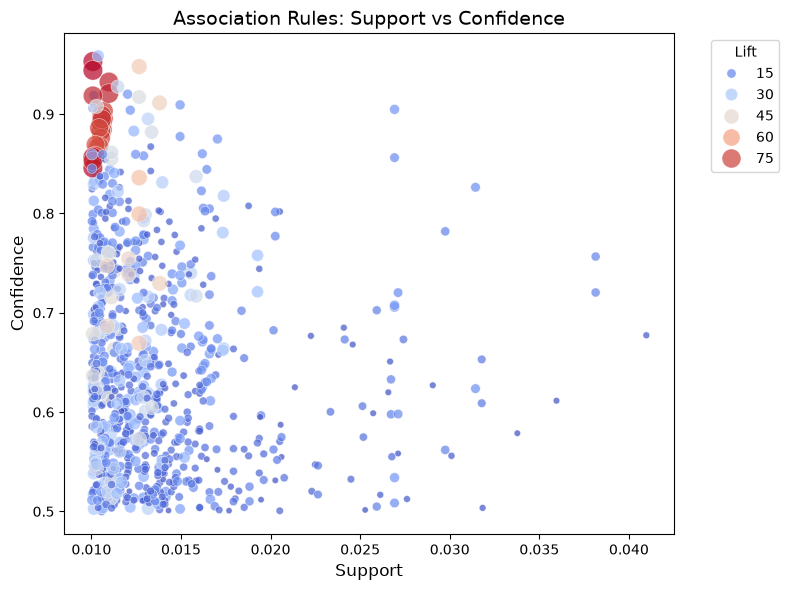

In [9]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='support', y='confidence', size='lift', hue='lift', 
                data=rules, palette='coolwarm', sizes=(20, 200), alpha=0.7)

plt.title('Association Rules: Support vs Confidence', fontsize=14)
plt.xlabel('Support', fontsize=12)
plt.ylabel('Confidence', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Lift')
plt.tight_layout()
plt.show()